walkthrough: https://docs.pytorch.org/tutorials/intermediate/reinforcement_q_learning.html

# setup + imports

In [1]:
%pip install "gymnasium[classic_control]"

Note: you may need to restart the kernel to use updated packages.


In [2]:
import gymnasium as gym
import math
import random
import matplotlib
import matplotlib.pyplot as plt
from collections import namedtuple, deque
from itertools import count

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

In [3]:
env = gym.make("CartPole-v1")

is_ipython = 'inline' in matplotlib.get_backend()
if is_ipython:
    from IPython import display

plt.ion()

device = torch.device(
    "cuda" if torch.cuda.is_available() else
    "mps" if torch.backends.mps.is_available() else
    "cpu"
)

# nu sunt necesare astea dar why not
seed = 42
random.seed(seed)
torch.manual_seed(seed)
env.reset(seed=seed)
env.action_space.seed(seed)
env.observation_space.seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed(seed)

## replay memory

In [4]:
Transition = namedtuple("Transition", 
                       ('state', 'action', 'next_state', 'reward'))

class ReplayMemory(object):
    def __init__(self, capacity):
        self.memory = deque([], maxlen=capacity)
    def push(self, *args):
        self.memory.append(Transition(*args))
    def sample(self, batch_size):
        return random.sample(self.memory, batch_size)
    def __len__(self):
        return len(self.memory)

# DQN algorithm

## Q network

In [5]:
class DQN(nn.Module):
    def __init__(self, n_obs, n_act):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_obs, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, n_act),
        )
    def forward(self, x):
        return self.net(x)
        

In [6]:
BATCH_SIZE = 128
GAMMA = 0.99
EPS_START = 0.9
EPS_END = 0.01
EPS_DECAY = 2500
TAU = 0.005
LR = 3e-4

In [7]:
n_actions = env.action_space.n # nr de actiuni
state, info = env.reset() # da start la joc si iti da prima stare
n_observations = len(state) 

# ok deci le initializam cu modelul pe amandoua (o sa isi dea separate pe parcurs, policy se schimba mai mult decat target)
# ca sa imceapa cu weightsurile la fel bagam load state dict
policy_net = DQN(n_observations, n_actions).to(device)
target_net = DQN(n_observations, n_actions).to(device)
target_net.load_state_dict(policy_net.state_dict())

# amsgrad pastreaza the largest average pe care l-a vazt
# ca sa nu avem dropuri wild if the average suddenly drops 
# (e chestie minora tho, kinda optional)
optimizer = optim.AdamW(policy_net.parameters(), lr=LR, amsgrad=True)
memory = ReplayMemory(10000)

steps_done = 0

In [8]:
def select_action(state):
    global steps_done
    sample = random.random()
    eps_threshold = EPS_END + (EPS_START - EPS_END) * math.exp(-1. * steps_done / EPS_DECAY)
    steps_done += 1
    if sample > eps_threshold:
        with torch.no_grad():
            return policy_net(state).max(1).indices.view(1, 1)
            # policy_net(state) gives the Q-values, shape [1, 2] (one state, two actions), e.g. [[0.3, 0.8]].
            # .max(1) takes the max along each row and returns both the values and their positions. .indices keeps the positions, here [1]. 
            # .view(1, 1) reshapes it to [[1]], the shape the rest of the code expects for an action.
    else: 
        return torch.tensor([[env.action_space.sample()]], device=device, dtype=torch.long)
        # luam cv random

In [9]:
episode_durations = []
# cat a stat the pole up, so cu cat mai mult cu atat mai bine

def plot_durations(show_result=False):
    plt.figure(1)
    durations_t = torch.tensor(episode_durations, dtype=torch.float)
    if show_result:
        plt.title('Result')
    else:
        plt.clf()
        plt.title('Training...')
    plt.xlabel('Episode')
    plt.ylabel('Duration')
    plt.plot(durations_t.numpy())

    if len(durations_t) >= 100:
        means = durations_t.unfold(0, 100, 1).mean(1).view(-1)
        means = torch.cat((torch.zeros(99), means))
        plt.plot(means.numpy())
        # ok deci unfoldd e un fel de sliding window de 100 de val one step at a time along directie 0abs
        # .cat e acolo ca sa avem cum sa incepem primul slide  

    plt.pause(0.001) 
    if is_ipython:
        if not show_result:
            display.display(plt.gcf())
            display.clear_output(wait=True)
        else:
            display.display(plt.gcf())

## training loop

In [11]:
def optimize_model():
    if len(memory) < BATCH_SIZE:
        return
    transitions = memory.sample(BATCH_SIZE)
    states, actions, next_states, rewards = [], [], [], []
    for t in transitions:
        states.append(t.state)
        actions.append(t.action)
        next_states.append(t.next_state)
        rewards.append(t.reward)

    # vedem daca s-a terminat sau nu dupa aceasta tranzitie
    mask = []
    non_final = []
    for s in next_states:
        mask.append(s is not None)
        if s is not None:
            non_final.append(s)
    non_final_mask = torch.tensor(mask, device=device, dtype=torch.bool)
    non_final_next_states = torch.cat(non_final)
    
    state_batch = torch.cat(states)
    action_batch = torch.cat(actions)
    reward_batch = torch.cat(rewards)

    rows = torch.arange(len(action_batch))
    q_all = policy_net(state_batch)
    state_action_values = q_all[rows, action_batch.squeeze(1)]
    # pt ca policy net da un tabel, vrem sa luam pe fiecare row doar coloana de la action_batch,abs
    # pt ca vrem doar Q-value de la actiunea care chiar a fost luata in acea stare
    # merge si state_action_values = policy_net(state_batch).gather(1, action_batch)

    next_state_values = torch.zeros(BATCH_SIZE, device=device)
    with torch.no_grad():
        next_state_values[non_final_mask] = target_net(non_final_next_states).max(1).values
    expected_state_action_values = (next_state_values * GAMMA) + reward_batch

    criterion = nn.SmoothL1Loss()
    loss = criterion(state_action_values, expected_state_action_values)

    optimizer.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_value_(policy_net.parameters(), 100)
    optimizer.step()
        
    

# training

In [12]:
if torch.cuda.is_available() or torch.backends.mps.is_available():
    num_episodes = 600
else:
    num_episodes = 50

Complete


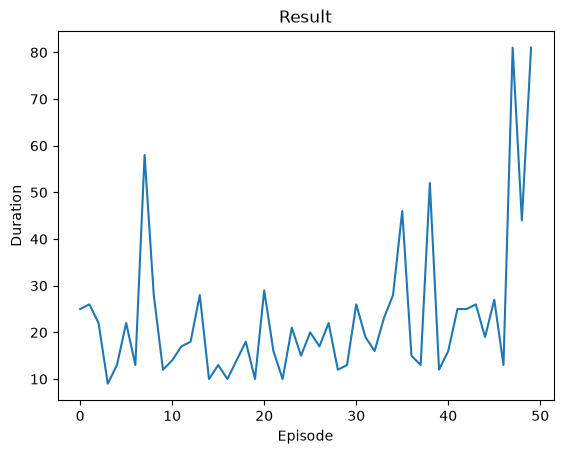

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [13]:
for idx_ep in range(num_episodes):
    state, info = env.reset()
    state = torch.tensor(state, dtype=torch.float32, device=device).unsqueeze(0)
    for t in count():
        action = select_action(state)
        # truncated e true daca a fost cut off episodul de a time limit
        observation, reward, terminated, truncated, _ = env.step(action.item())
        reward = torch.tensor([reward], device=device)
        done = terminated or truncated

        if terminated:
            next_state = None
        else:
            next_state = torch.tensor(observation, dtype=torch.float32, device=device).unsqueeze(0)

        memory.push(state, action, next_state, reward)
        state = next_state
        optimize_model()

        target_net_state_dict = target_net.state_dict()
        policy_net_state_dict = policy_net.state_dict()
        for key in policy_net_state_dict:
            target_net_state_dict[key] = policy_net_state_dict[key]*TAU + target_net_state_dict[key]*(1-TAU)
        target_net.load_state_dict(target_net_state_dict)

        if done:
            episode_durations.append(t + 1)
            plot_durations()
            break

print('Complete')
plot_durations(show_result=True)
plt.ioff()
plt.show()